In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



In [1]:

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN

In [22]:
df = pd.read_csv("crime_data.csv")

In [23]:
df.head()

,Unnamed: 0,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0
3,Arkansas,8.8,190,50,19.5
4,California,9.0,276,91,40.6


In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  50 non-null     object 
 1   Murder      50 non-null     float64
 2   Assault     50 non-null     int64  
 3   UrbanPop    50 non-null     int64  
 4   Rape        50 non-null     float64
dtypes: float64(2), int64(2), object(1)
memory usage: 2.1+ KB


In [25]:
df.describe()

,Murder,Assault,UrbanPop,Rape
count,50.00000,50.000000,50.000000,50.000000
mean,7.78800,170.760000,65.540000,21.232000
std,4.35551,83.337661,14.474763,9.366385
min,0.80000,45.000000,32.000000,7.300000
25%,4.07500,109.000000,54.500000,15.075000
50%,7.25000,159.000000,66.000000,20.100000
75%,11.25000,249.000000,77.750000,26.175000
max,17.40000,337.000000,91.000000,46.000000


In [26]:
df.drop('Unnamed: 0',axis=1,inplace=True)

In [27]:
df.corr()

,Murder,Assault,UrbanPop,Rape
Murder,1.000000,0.801873,0.069573,0.563579
Assault,0.801873,1.000000,0.258872,0.665241
UrbanPop,0.069573,0.258872,1.000000,0.411341
Rape,0.563579,0.665241,0.411341,1.000000


In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler



In [29]:
std1 = MinMaxScaler()
df_std = pd.DataFrame(std1.fit_transform(df),columns = df.columns)

In [30]:
std2 = StandardScaler()
df_std_normaliz = pd.DataFrame(std2.fit_transform(df),columns=df.columns)

In [31]:
# df_std

In [32]:
# df

For min max scaler


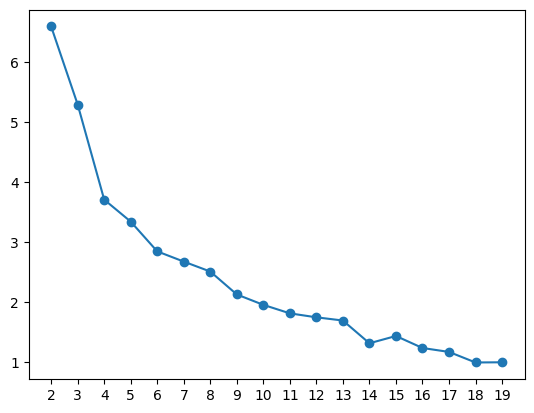

In [36]:
print("For min max scaler")
wcc=[]
for k in range(2,20):
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(df_std)
    
    wcc.append(kmeans.inertia_)
plt.xticks(range(2,20))

plt.plot(range(2,20),wcc,marker='o')


using normalization


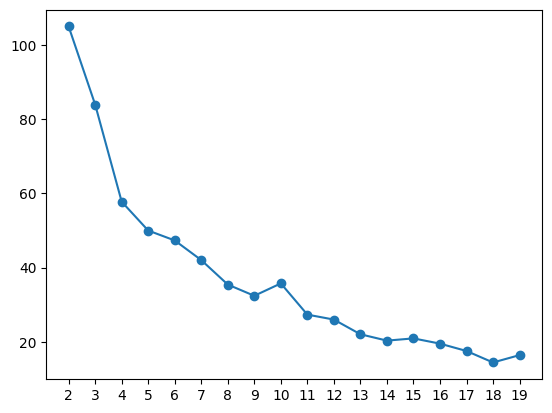

In [37]:
print("using normalization")
wcc=[]
for k in range(2,20):
    kmeans = KMeans(n_clusters=k)
    kmeans.fit(df_std_normaliz)
    
    wcc.append(kmeans.inertia_)
plt.xticks(range(2,20))

plt.plot(range(2,20),wcc,marker='o')

In [46]:
# from sklearn.cluster import KMeans
print("using min max ")
k = 3
kmeans = KMeans(n_clusters=k)
kmeans.fit(df_std)
df['awards_prediction']=kmeans.labels_
from sklearn.metrics import silhouette_score

# find hte labels of every data point
labels = kmeans.labels_

# finding silhouette score

score = silhouette_score(df_std,labels)
print(f"Silhouette score = {score:.2f}")

using min max 
Silhouette score = 0.36


In [45]:
print("using std normalization")
k = 3
kmeans = KMeans(n_clusters=k)
kmeans.fit(df_std_normaliz)
df['awards_prediction']=kmeans.labels_
from sklearn.metrics import silhouette_score

# find hte labels of every data point
labels = kmeans.labels_

# finding silhouette score

score = silhouette_score(df_std,labels)
print(f"Silhouette score = {score:.2f}")

using std normalization
Silhouette score = 0.37


In [114]:
# df['awards_prediction'].unique()

In [47]:

from sklearn.cluster import AgglomerativeClustering
cluster_info = AgglomerativeClustering(n_clusters=5)
cluster_info.fit(df_std)

,n_clusters,5
,metric,'euclidean'
,memory,None
,connectivity,None
,compute_full_tree,'auto'
,linkage,'ward'
,distance_threshold,None
,compute_distances,False


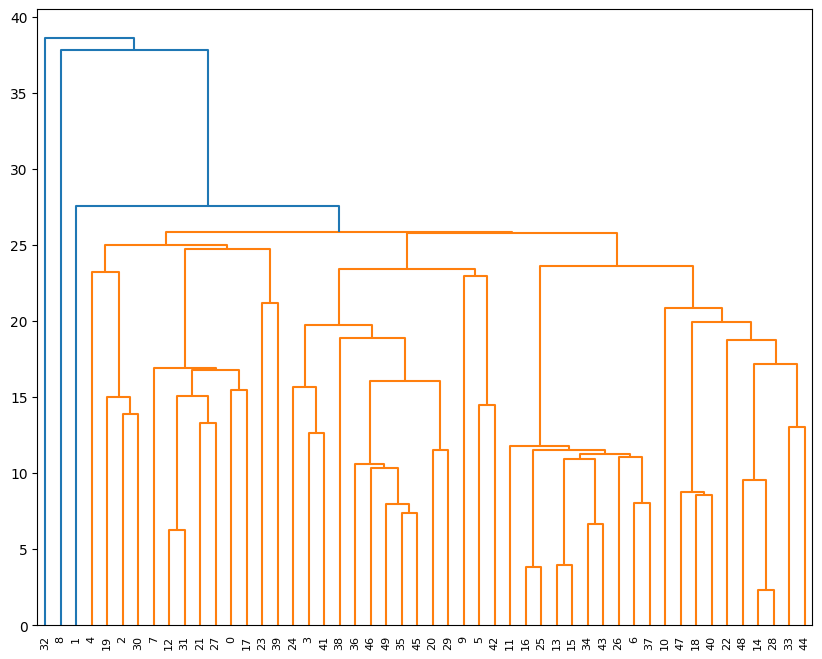

In [48]:
from scipy.cluster import hierarchy

# get the linkage information
linkage = hierarchy.linkage(df, 'single')
plt.figure(figsize=(10,8))
# create a dendrogram using linkage data
dendrogram = hierarchy.dendrogram(linkage)

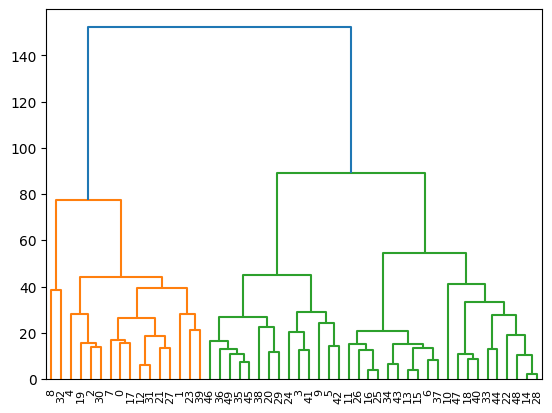

In [49]:
linkage = hierarchy.linkage(df, 'average')
dendrogram = hierarchy.dendrogram(linkage)

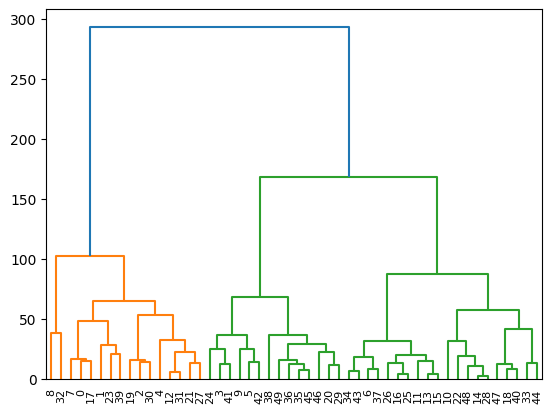

In [50]:
linkage = hierarchy.linkage(df, 'complete')
dendrogram = hierarchy.dendrogram(linkage)